# MET CS555: Homework 4

Chris Davis

## Questions

The data is from a Canadian 1970 census which collected information about specific occupations. Data collected was used to develop a regression model to predict prestige for all occupations. Use R or Python to calculate the quantities and generate the visual summaries requested below.

<em style="color:#333333">(1) To get a sense of the data, generate a scatterplot to examine the association between prestige score and years of education. Briefly describe the form, direction, and strength of the association between the variables. Calculate the correlation coefficient. (3 points)</em>

Education is on the x-axis and prestige is on the y-axis.

The points show a positive association. Occupations with more education tend to have higher prestige. The form looks roughly linear, and the relationship is strong. The correlation is r = 0.850. See appendix, question 1.

![Prestige vs Education](prestige_education_scatter.png)

<em style="color:#333333">(2) Perform a simple linear regression with prestige score and years of education, and briefly summarize your conclusions (no need to do the 5-step procedure here). Generate a residual plot. Assess whether the model assumptions are met. Are there any outliers or influence points? If so, identify them by ID and comment on the effect of each on the regression. (4 points)</em>

Predicted prestige = -10.732 + 5.361 × (years of education).

Each extra year of education is associated with about 5.36 more prestige points. R-squared = 0.723, so education explains about 72.3% of the variation in prestige. The slope is clearly nonzero (t = 16.15, p is tiny).

![Simple Regression Residual Plot](simple_residual_plot.png)

The residual plot looks mostly okay. There is some scatter, but no strong curve or fan shape. A straight-line model is a reasonable start.

Possible outliers (|studentized residual| > 2): IDs 41, 46, 53, 54, and 67.

Influence points (Cook's D > 4/n): IDs 24, 53, and 67.
- ID 24 PHYSICIANS: omitting it lowers the slope from 5.361 to 5.271.
- ID 53 NEWSBOYS: omitting it lowers the slope to 5.322.
- ID 67 FARMERS: omitting it raises the slope to 5.458.

The positive relationship stays in all cases. I keep all observations. See appendix, question 2.

<em style="color:#333333">(3) Calculate the least squares regression equation that predicts prestige score from education, income, and percentage of women. Formally test (using the 5-step procedure) whether the set of these predictors are associated with prestige score at the α = 0.05 level (Hint: You should be performing the global test). (3 points)</em>

Predicted prestige = -6.794 + 4.187 × Education + 0.001314 × Income - 0.00891 × Women.

1. Null hypothesis: all three slopes are 0. Alternative: at least one slope is not 0. Alpha = 0.05.
2. Global F statistic. Numerator df = 3, denominator df = 98.
3. Reject H0 if F > 2.697; otherwise, fail to reject H0.
4. F = 129.19. The p-value is about 6.26 × 10^-34.
5. F is greater than 2.697, so reject H0. The set of predictors is associated with prestige.

R-squared = 0.798. Adjusted R-squared = 0.792. See appendix, question 3.

<em style="color:#333333">(4) If the overall model was significant, summarize the information about the contribution of each variable separately at the same significance level as used for the overall model (no need to do a formal 5-step procedure for each one, just comment on the results of the tests). Provide interpretations for any estimates (of the slopes) that are significant. Calculate 95% confidence intervals for any estimates that are significant. (3 points)</em>

Education: t = 10.771, p < 0.0001. Significant. Holding income and percentage of women fixed, one more year of education is associated with about 4.187 more prestige points. 95% CI: (3.415, 4.958).

Income: t = 4.729, p < 0.0001. Significant. Holding education and percentage of women fixed, an extra $1,000 of income is associated with about 1.314 more prestige points. 95% CI per $1,000: (0.762, 1.865).

Women: t = -0.293, p = 0.770. Not significant. After accounting for education and income, there is not enough evidence that percentage of women is associated with prestige. See appendix, question 4.

<em style="color:#333333">(5) Generate a residual plot showing the fitted values from the regression against the residuals. Is the fit of the model reasonable? Are there any outliers or influence points? (3 points)</em>

![Multiple Regression Residual Plot](multiple_residual_plot.png)

The fit looks reasonable. Residuals are mostly scattered around 0 with no clear curve. R-squared is about 0.80.

Possible outliers (|studentized residual| > 2): IDs 29, 46, 53, 67, and 82.

High leverage: IDs 2, 17, 20, 24, and 84.

Influence points (Cook's D > 4/n): IDs 2, 20, 24, 27, 29, 41, 53, 54, 67, and 82. ID 2 GENERAL_MANAGERS has the largest Cook's distance (about 0.283). Omitting it changes the education slope from 4.187 to 3.947 and the income slope from 0.001314 to 0.001601. I still keep all observations. See appendix, question 5.

<em style="color:#333333">(6) Examine if there is a linear interaction between income and education level (examine if the interaction is significant)? (2 points)</em>

I add an Education × Income term to the model.

The interaction estimate is -0.000203. t = -2.623, p = 0.0101. At alpha = 0.05, the interaction is significant.

So the association between income and prestige depends on education. R-squared goes from 0.798 to 0.812. See appendix, question 6.

<em style="color:#333333">(7) Fill in the gaps in the following multiple answer question:</em>

<em style="color:#333333">As more independent variables are added to a multiple regression model, ___________ will increase; this is not always so with ___________, which will only increase if the additional variables add substantial explanatory power to the model.</em>

<em style="color:#333333">A) R²; adjusted R²</em>

<em style="color:#333333">B) adjusted R²; R²</em>

<em style="color:#333333">C) R²; the coefficient of determination</em>

<em style="color:#333333">D) the standard error of the estimate; R²</em>

<em style="color:#333333">Explain why? (2 points)</em>

Answer: A) R²; adjusted R²

R-squared cannot go down when you add predictors, because the larger model can always match the smaller one. Adjusted R-squared also accounts for how many predictors you use, so it only goes up when the new variables help enough. See appendix, question 7 (no code needed).

## Appendix: Code

In [ ]:
# Setup

%pip install numpy pandas matplotlib scipy statsmodels

In [14]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

%matplotlib inline


In [22]:
# Read the data

jobs = pd.read_csv("data.csv")
print("rows read =", len(jobs))
print(jobs.head())


rows read = 102
   ID           Occupation  Education  Income  Women  Prestige
0   1   GOV_ADMINISTRATORS      13.11   12351  11.16      68.8
1   2     GENERAL_MANAGERS      12.26   25879   4.02      69.1
2   3          ACCOUNTANTS      12.77    9271  15.70      63.4
3   4  PURCHASING_OFFICERS      11.42    8865   9.11      56.8
4   5             CHEMISTS      14.62    8403  11.68      73.5


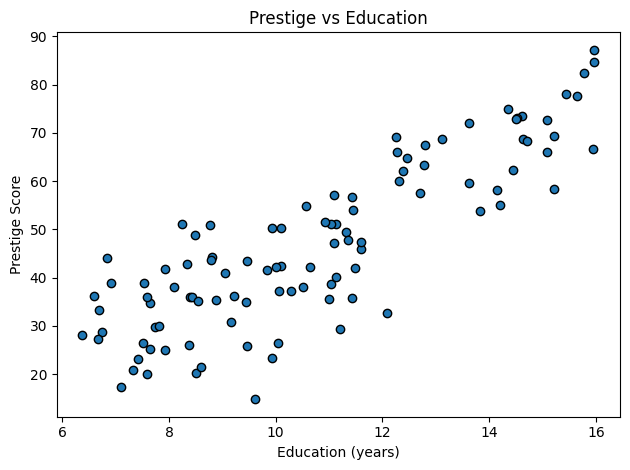

correlation = 0.85


In [23]:
# Question 1

x = jobs["Education"]
y = jobs["Prestige"]

plt.scatter(x, y, edgecolor="black")
plt.xlabel("Education (years)")
plt.ylabel("Prestige Score")
plt.title("Prestige vs Education")
plt.tight_layout()
plt.savefig("prestige_education_scatter.png")
plt.show()

r = x.corr(y)
print("correlation =", round(r, 3))


Intercept   -10.7320
Education     5.3609
dtype: float64
t = 16.148
p-value = 1.286264142966709e-29
R-squared = 0.723


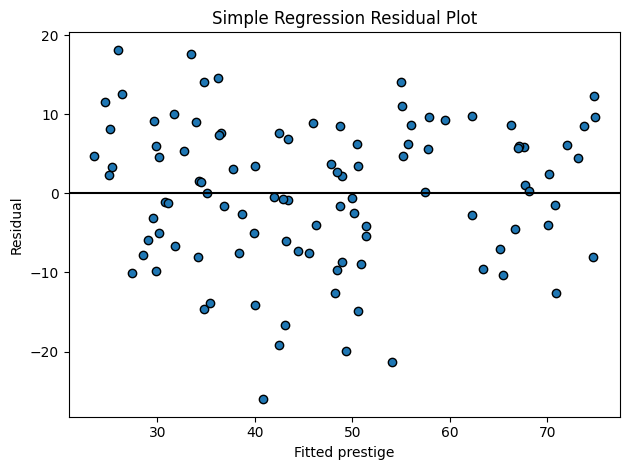

outliers |studentized residual| > 2:
 ID                Occupation
 41               FILE_CLERKS
 46                COLLECTORS
 53                  NEWSBOYS
 54 SERVICE_STATION_ATTENDANT
 67                   FARMERS

Cook's D > 4/n:
 ID Occupation  Cooks_D
 24 PHYSICIANS   0.0468
 53   NEWSBOYS   0.0480
 67    FARMERS   0.0635


In [24]:
# Question 2

simple = smf.ols("Prestige ~ Education", data=jobs).fit()
print(simple.params.round(4))
print("t =", round(simple.tvalues["Education"], 3))
print("p-value =", simple.pvalues["Education"])
print("R-squared =", round(simple.rsquared, 3))

plt.scatter(simple.fittedvalues, simple.resid, edgecolor="black")
plt.axhline(0, color="black")
plt.xlabel("Fitted prestige")
plt.ylabel("Residual")
plt.title("Simple Regression Residual Plot")
plt.tight_layout()
plt.savefig("simple_residual_plot.png")
plt.show()

inf = simple.get_influence()
stud = inf.resid_studentized_external
cook = inf.cooks_distance[0]
n = len(jobs)

print("outliers |studentized residual| > 2:")
print(jobs.loc[np.abs(stud) > 2, ["ID", "Occupation"]].to_string(index=False))
print()
print("Cook's D > 4/n:")
print(jobs.loc[cook > 4 / n, ["ID", "Occupation"]].assign(Cooks_D=np.round(cook[cook > 4 / n], 4)).to_string(index=False))


In [25]:
# Question 3

multiple = smf.ols("Prestige ~ Education + Income + Women", data=jobs).fit()
print(multiple.params.round(6))
print()

anova = pd.DataFrame({
    "DF": [int(multiple.df_model), int(multiple.df_resid), int(multiple.nobs) - 1],
    "SS": [multiple.ess, multiple.ssr, multiple.centered_tss],
    "MS": [multiple.ess / multiple.df_model, multiple.ssr / multiple.df_resid, np.nan],
    "F": [multiple.fvalue, np.nan, np.nan],
}, index=["Regression", "Residual", "Total"]).round(2)
print(anova.to_string())
print()

crit = stats.f.ppf(0.95, multiple.df_model, multiple.df_resid)
print("F =", round(multiple.fvalue, 4))
print("critical F =", round(crit, 4))
print("p-value =", multiple.f_pvalue)
print("R-squared =", round(multiple.rsquared, 3))
print("adjusted R-squared =", round(multiple.rsquared_adj, 3))


Intercept   -6.794334
Education    4.186637
Income       0.001314
Women       -0.008905
dtype: float64

             DF        SS       MS       F
Regression    3  23861.86  7953.95  129.19
Residual     98   6033.57    61.57     NaN
Total       101  29895.43      NaN     NaN

F = 129.1917
critical F = 2.6974
p-value = 6.25906102903507e-34
R-squared = 0.798
adjusted R-squared = 0.792


In [26]:
# Question 4

ci = multiple.conf_int()
coef = pd.DataFrame({
    "Estimate": multiple.params,
    "SE": multiple.bse,
    "t": multiple.tvalues,
    "p-value": multiple.pvalues,
    "95% CI lower": ci[0],
    "95% CI upper": ci[1],
}).round(6)
print(coef.to_string())
print()
print("Income effect per $1,000:")
print((coef.loc["Income", ["Estimate", "95% CI lower", "95% CI upper"]] * 1000).round(4).to_string())


           Estimate        SE          t   p-value  95% CI lower  95% CI upper
Intercept -6.794334  3.239089  -2.097607  0.038513    -13.222200     -0.366468
Education  4.186637  0.388701  10.770835  0.000000      3.415272      4.958002
Income     0.001314  0.000278   4.728759  0.000008      0.000762      0.001865
Women     -0.008905  0.030407  -0.292865  0.770245     -0.069247      0.051437

Income effect per $1,000:
Estimate        1.314
95% CI lower    0.762
95% CI upper    1.865


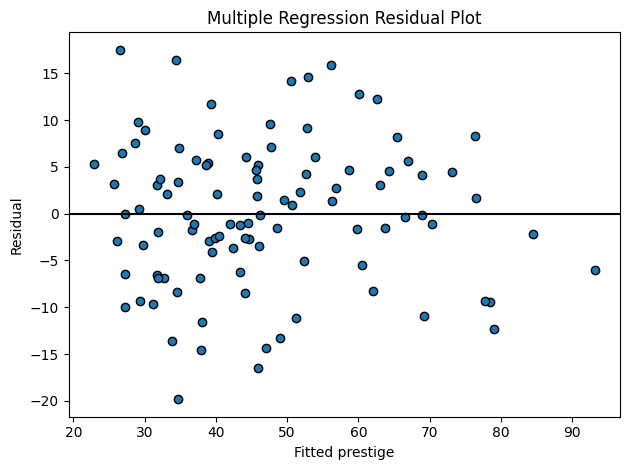

outliers |studentized residual| > 2:
 ID         Occupation
 29   PHYSIO_THERAPSTS
 46         COLLECTORS
 53           NEWSBOYS
 67            FARMERS
 82 ELECTRONIC_WORKERS

high leverage > 0.0784 :
 ID            Occupation
  2      GENERAL_MANAGERS
 17               LAWYERS
 20             MINISTERS
 24            PHYSICIANS
 84 SEWING_MACH_OPERATORS

Cook's D > 4/n:
 ID                Occupation  Cooks_D
  2          GENERAL_MANAGERS   0.2833
 20                 MINISTERS   0.0839
 24                PHYSICIANS   0.0617
 27                    NURSES   0.0519
 29          PHYSIO_THERAPSTS   0.0550
 41               FILE_CLERKS   0.0396
 53                  NEWSBOYS   0.1177
 54 SERVICE_STATION_ATTENDANT   0.0495
 67                   FARMERS   0.0490
 82        ELECTRONIC_WORKERS   0.0493


In [27]:
# Question 5

plt.scatter(multiple.fittedvalues, multiple.resid, edgecolor="black")
plt.axhline(0, color="black")
plt.xlabel("Fitted prestige")
plt.ylabel("Residual")
plt.title("Multiple Regression Residual Plot")
plt.tight_layout()
plt.savefig("multiple_residual_plot.png")
plt.show()

inf2 = multiple.get_influence()
stud2 = inf2.resid_studentized_external
cook2 = inf2.cooks_distance[0]
lev2 = inf2.hat_matrix_diag
p = len(multiple.params)

print("outliers |studentized residual| > 2:")
print(jobs.loc[np.abs(stud2) > 2, ["ID", "Occupation"]].to_string(index=False))
print()
print("high leverage >", round(2 * p / n, 4), ":")
print(jobs.loc[lev2 > 2 * p / n, ["ID", "Occupation"]].to_string(index=False))
print()
print("Cook's D > 4/n:")
print(jobs.loc[cook2 > 4 / n, ["ID", "Occupation"]].assign(Cooks_D=np.round(cook2[cook2 > 4 / n], 4)).to_string(index=False))


In [28]:
# Question 6

interaction = smf.ols("Prestige ~ Education * Income + Women", data=jobs).fit()
print(interaction.params.round(6))
print()
print("interaction t =", round(interaction.tvalues["Education:Income"], 3))
print("interaction p-value =", round(interaction.pvalues["Education:Income"], 4))
print("R-squared =", round(interaction.rsquared, 3))
print("adjusted R-squared =", round(interaction.rsquared_adj, 3))


Intercept          -22.650217
Education            5.356351
Income               0.004089
Education:Income    -0.000203
Women                0.010689
dtype: float64

interaction t = -2.623
interaction p-value = 0.0101
R-squared = 0.812
adjusted R-squared = 0.804
